# Fig. 2b — rank percentile on the DecoyFinder and DeepCoy decoy libraries

Reads the per-pair source data shipped alongside this notebook, so the figure can be
redrawn without re-running any model:

    raw_data/Fig2/Fig2b_rank_percentile_per_pair.csv

One row per (model, decoy library, RNA-ligand pair): 6,875 rows over six methods and
three libraries. `rank_percentile` is the value the box plots summarise -- 1.0 means the
true binder outranked every decoy.

SMARTBind's rows can be regenerated from the released weights and data with

    python decoyfinder_deepcoy_inference.py

which writes the same schema; a full re-run reproduces the values below to four decimal
places. The five baselines were produced by their own authors' code and are shipped as
results only.

In [1]:
import pandas as pd

# Locate the Source Data.  Download `raw_data` from the link named in the
# repository README and unpack it at the repository root; this walks up to find it, so
# the notebook runs from anywhere inside the checkout.
from pathlib import Path


def find_raw_data():
    here = Path.cwd().resolve()
    for folder in (here, *here.parents):
        candidate = folder / "raw_data"
        if candidate.is_dir():
            return candidate
    raise SystemExit(
        "\nCould not find `raw_data/`.\n\n"
        "The raw data is not provided with the release. Reproduce the underlying\n"
        "numbers with the inference scripts.\n")


RAW = find_raw_data()

SOURCE = RAW / "Fig2" / "Fig2b_rank_percentile_per_pair.csv"
per_pair = pd.read_csv(SOURCE)

# {model: {library: [rank percentile, ...]}} - the shape the plotting cell expects
benchmark_results = {
    model: {lib: block["rank_percentile"].tolist()
            for lib, block in rows.groupby("decoy_library")}
    for model, rows in per_pair.groupby("model")
}

print(f"{len(per_pair):,} pairs | {per_pair.model.nunique()} methods x "
      f"{per_pair.decoy_library.nunique()} libraries")
for model in ["SMARTBind", "RNAmigos2", "DrugBAN_RNA", "GraphDTA_RNA", "RNAsmol", "GerNA-Bind"]:
    line = "  ".join(
        f"{lib}: n={len(benchmark_results[model][lib]):>3} "
        f"mean={pd.Series(benchmark_results[model][lib]).mean():.4f}"
        for lib in ["DecoyFinder", "DeepCoy-DUD-E", "DeepCoy-DEKOIS"])
    print(f"{model:<14} {line}")

6,875 pairs | 6 methods x 3 libraries
SMARTBind      DecoyFinder: n=336 mean=0.9066  DeepCoy-DUD-E: n=429 mean=0.9111  DeepCoy-DEKOIS: n=429 mean=0.9103
RNAmigos2      DecoyFinder: n=332 mean=0.8065  DeepCoy-DUD-E: n=419 mean=0.8364  DeepCoy-DEKOIS: n=419 mean=0.8285
DrugBAN_RNA    DecoyFinder: n=336 mean=0.8693  DeepCoy-DUD-E: n=429 mean=0.8245  DeepCoy-DEKOIS: n=429 mean=0.8423
GraphDTA_RNA   DecoyFinder: n=336 mean=0.8445  DeepCoy-DUD-E: n=429 mean=0.8237  DeepCoy-DEKOIS: n=429 mean=0.8300
RNAsmol        DecoyFinder: n=336 mean=0.8690  DeepCoy-DUD-E: n=429 mean=0.6098  DeepCoy-DEKOIS: n=429 mean=0.6715
GerNA-Bind     DecoyFinder: n=295 mean=0.8109  DeepCoy-DUD-E: n=317 mean=0.7857  DeepCoy-DEKOIS: n=317 mean=0.8054


Model order by average performance (descending):
  SMARTBind: mean=0.9096, std=0.2337, 95% CI=(0.8963, 0.9228), n=1194
  DrugBAN_RNA: mean=0.8435, std=0.2457, 95% CI=(0.8296, 0.8574), n=1194
  GraphDTA_RNA: mean=0.8318, std=0.2376, 95% CI=(0.8183, 0.8453), n=1194
  RNAmigos2: mean=0.8251, std=0.2327, 95% CI=(0.8117, 0.8384), n=1170
  GerNA-Bind: mean=0.8004, std=0.2628, 95% CI=(0.7835, 0.8173), n=929
  RNAsmol: mean=0.7049, std=0.2543, 95% CI=(0.6905, 0.7193), n=1194

DecoyFinder statistics:
  SMARTBind: mean=0.9066, std=0.2416, 95% CI=(0.8808, 0.9324)
  DrugBAN_RNA: mean=0.8693, std=0.2148, 95% CI=(0.8463, 0.8922)
  GraphDTA_RNA: mean=0.8445, std=0.2272, 95% CI=(0.8202, 0.8688)
  RNAmigos2: mean=0.8065, std=0.2047, 95% CI=(0.7845, 0.8285)
  GerNA-Bind: mean=0.8109, std=0.2682, 95% CI=(0.7803, 0.8415)
  RNAsmol: mean=0.8690, std=0.2199, 95% CI=(0.8455, 0.8926)

DeepCoy-DUD-E statistics:
  SMARTBind: mean=0.9111, std=0.2310, 95% CI=(0.8892, 0.9330)
  DrugBAN_RNA: mean=0.8245, std=0.2643

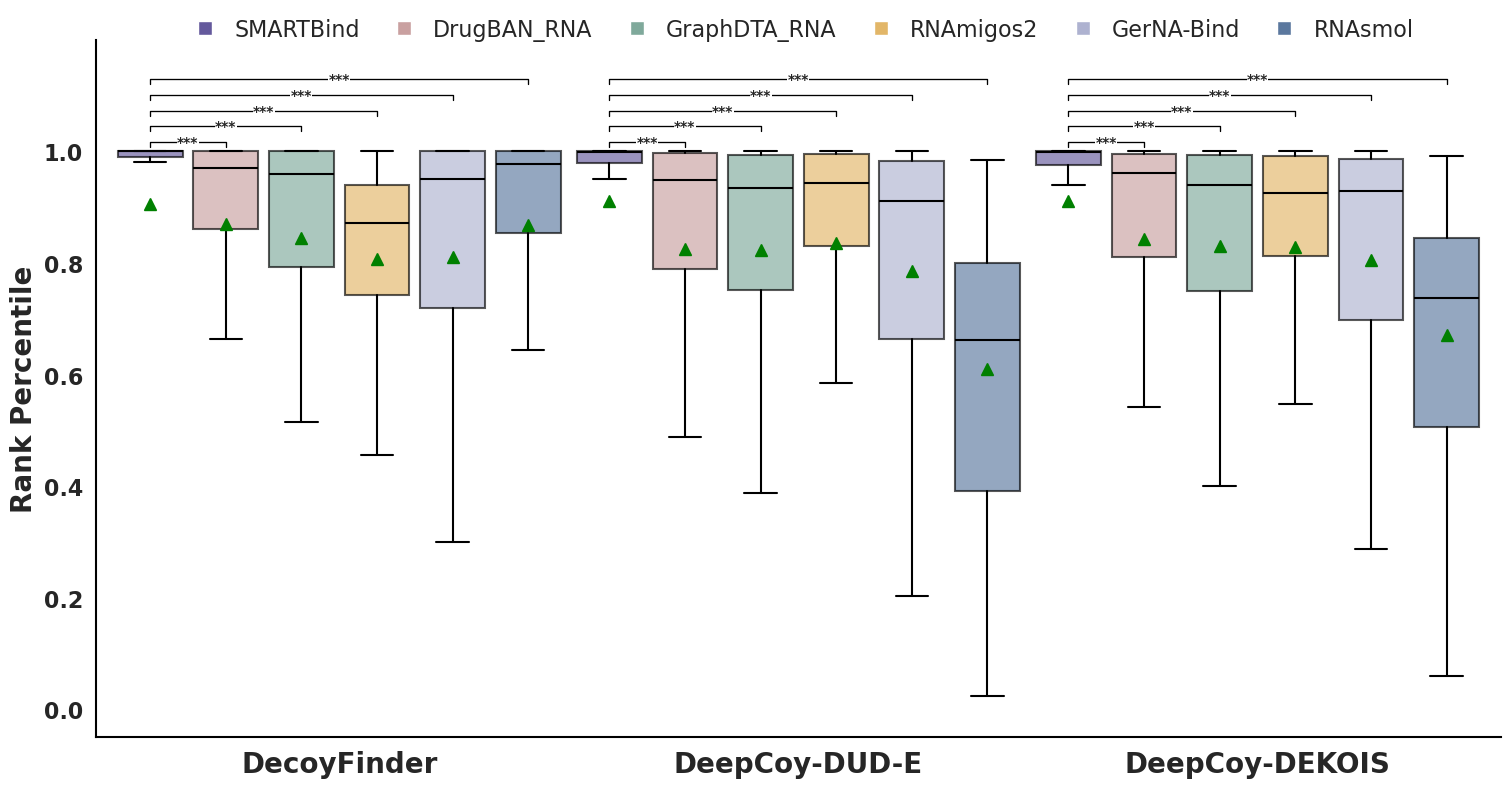


=== Wilcoxon Rank-Sum Test Results (one-tailed: SMARTBind > other) ===

Dataset: DecoyFinder
  SMARTBind vs DrugBAN_RNA: p = 6.25e-17 (***)
  SMARTBind vs GraphDTA_RNA: p = 9.23e-21 (***)
  SMARTBind vs RNAmigos2: p = 4.56e-48 (***)
  SMARTBind vs GerNA-Bind: p = 1.82e-20 (***)
  SMARTBind vs RNAsmol: p = 1.90e-10 (***)

Dataset: DeepCoy-DUD-E
  SMARTBind vs DrugBAN_RNA: p = 7.11e-30 (***)
  SMARTBind vs GraphDTA_RNA: p = 1.97e-37 (***)
  SMARTBind vs RNAmigos2: p = 2.30e-25 (***)
  SMARTBind vs GerNA-Bind: p = 6.72e-40 (***)
  SMARTBind vs RNAsmol: p = 2.89e-93 (***)

Dataset: DeepCoy-DEKOIS
  SMARTBind vs DrugBAN_RNA: p = 1.05e-28 (***)
  SMARTBind vs GraphDTA_RNA: p = 8.28e-35 (***)
  SMARTBind vs RNAmigos2: p = 5.52e-33 (***)
  SMARTBind vs GerNA-Bind: p = 3.90e-34 (***)
  SMARTBind vs RNAsmol: p = 6.53e-88 (***)



In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from scipy.stats import mannwhitneyu

model_colors = {
    "SMARTBind": "#64599C",
    "RNAmigos1": "#F4E9B3", 
    "RNAmigos2": "#E2B668",
    "RNAsmol": "#5B789E",
    "GerNA-Bind": "#AEB2D0",
    "DrugBAN_RNA": "#C9A0A0",
    "GraphDTA_RNA": "#7FA99B",
    "AutoDock-GPU": "#E8927C"
}

sns.set_style("whitegrid")
plt.rcParams['font.size'] = 12

models_all = ['SMARTBind', 'RNAmigos2', 'DrugBAN_RNA', 'GraphDTA_RNA', 'RNAsmol', 'GerNA-Bind']
datasets = ['DecoyFinder', 'DeepCoy-DUD-E', 'DeepCoy-DEKOIS']

fig, ax = plt.subplots(figsize=(15.5, 8))

plot_data = []
for model in models_all:
    if model == 'AutoDock-GPU':
        for dataset in datasets:
            label = dataset  # matches keys in autodock_gpu_percentiles
            for val in autodock_gpu_percentiles.get(label, []):
                plot_data.append({'Model': model, 'Dataset': dataset, 'Score': val})
    else:
        for dataset in datasets:
            values = benchmark_results[model][dataset]
            for val in values:
                plot_data.append({'Model': model, 'Dataset': dataset, 'Score': val})

df = pd.DataFrame(plot_data)


def summarize_scores(scores):
    values = np.asarray(scores, dtype=float)
    n = len(values)
    mean_val = values.mean() if n else np.nan
    if n > 1:
        std_val = values.std(ddof=1)
        ci_margin = 1.96 * std_val / np.sqrt(n)
    elif n == 1:
        std_val = 0.0
        ci_margin = 0.0
    else:
        std_val = np.nan
        ci_margin = np.nan
    return {
        'n': n,
        'mean': mean_val,
        'std': std_val,
        'ci_low': mean_val - ci_margin if n else np.nan,
        'ci_high': mean_val + ci_margin if n else np.nan,
    }

# Sort models by average performance across all datasets (descending)
model_avg = {model: df[df['Model'] == model]['Score'].mean() for model in models_all}
models_all = sorted(models_all, key=lambda m: model_avg[m], reverse=True)
print("Model order by average performance (descending):")
for m in models_all:
    stats = summarize_scores(df[df['Model'] == m]['Score'].values)
    print(
        f"  {m}: mean={stats['mean']:.4f}, std={stats['std']:.4f}, "
        f"95% CI=({stats['ci_low']:.4f}, {stats['ci_high']:.4f}), n={stats['n']}"
    )

colors = [model_colors.get(model, '#808080') for model in models_all]
for dataset in datasets:
    print(f"\n{dataset} statistics:")
    for model in models_all:
        model_scores = df[(df['Model'] == model) & (df['Dataset'] == dataset)]['Score'].values
        stats = summarize_scores(model_scores)
        if stats['n'] == 0:
            print(f"  {model}: no data")
            continue
        print(
            f"  {model}: mean={stats['mean']:.4f}, std={stats['std']:.4f}, "
            f"95% CI=({stats['ci_low']:.4f}, {stats['ci_high']:.4f})"
        )

n_models = len(models_all)
n_datasets = len(datasets)
box_width = 0.12  
gap = 0.02  
group_spacing = 0.85
dataset_centers = [i * group_spacing for i in range(n_datasets)]

def get_box_positions(dataset_center, n_models, box_width, gap):
    total_width = n_models * box_width + (n_models - 1) * gap
    start = dataset_center - total_width / 2 + box_width / 2
    return [start + i * (box_width + gap) for i in range(n_models)]

for d_idx, dataset in enumerate(datasets):
    positions = get_box_positions(dataset_centers[d_idx], n_models, box_width, gap)
    
    for m_idx, model in enumerate(models_all):
        model_data = df[(df['Model'] == model) & (df['Dataset'] == dataset)]['Score'].values
        if len(model_data) == 0:
            continue

        bp = ax.boxplot([model_data], positions=[positions[m_idx]], widths=box_width,
                       patch_artist=True, showmeans=True, showfliers=False,
                       meanprops={'marker': '^', 'markerfacecolor': 'green', 
                                  'markeredgecolor': 'green', 'markersize': 8},
                       medianprops={'color': 'black', 'linewidth': 1.5},
                       boxprops={'facecolor': model_colors[model], 'edgecolor': 'black', 'linewidth': 1.5, 'alpha': 0.65},
                       whiskerprops={'color': 'black', 'linewidth': 1.5},
                       capprops={'color': 'black', 'linewidth': 1.5})

legend_elements = [Line2D([0], [0], marker='s', color='w', 
                          markerfacecolor=model_colors.get(model, '#808080'),
                          markersize=10, label=model)
                   for model in models_all]
ax.legend(handles=legend_elements, fontsize=16, 
          frameon=False, fancybox=False, shadow=False, 
          loc='upper center', bbox_to_anchor=(0.5, 1.06),
          ncol=len(models_all), columnspacing=1, handletextpad=0.3)

ax.set_xlabel('', fontsize=20, fontweight='bold')
ax.set_ylabel('Rank Percentile', fontsize=20, fontweight='bold')
ax.set_xticks(dataset_centers)
ax.set_xticklabels(datasets)

ax.set_xlim(dataset_centers[0] - 0.45, dataset_centers[-1] + 0.45)
ax.tick_params(axis='both', labelsize=16, width=2, length=6)
for label in ax.get_xticklabels():
    label.set_fontweight('bold')
    label.set_fontsize(20)
for label in ax.get_yticklabels():
    label.set_fontweight('bold')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(True)
ax.spines['bottom'].set_visible(True)
ax.spines['left'].set_linewidth(1.5)
ax.spines['left'].set_color('black')
ax.spines['bottom'].set_linewidth(1.5)
ax.spines['bottom'].set_color('black')

ax.grid(False)

# Wilcoxon rank-sum test (one-tailed): SMARTBind vs other models
def get_significance_symbol(p_value):
    if p_value < 0.001:
        return '***'
    elif p_value < 0.01:
        return '**'
    elif p_value < 0.05:
        return '*'
    else:
        return 'n.s.'

y_max = df['Score'].max()
line_height = 0.018 
text_offset = 0.0  

for d_idx, dataset in enumerate(datasets):
    positions = get_box_positions(dataset_centers[d_idx], n_models, box_width, gap)
    smartbind_pos_idx = models_all.index('SMARTBind')  
    smartbind_scores = df[(df['Model'] == 'SMARTBind') & (df['Dataset'] == dataset)]['Score'].values
    
    dataset_max = df[df['Dataset'] == dataset]['Score'].max()
    current_height = dataset_max + 0.008
    
    for m_idx, model in enumerate(models_all):
        if model == 'SMARTBind':
            continue
        model_scores = df[(df['Model'] == model) & (df['Dataset'] == dataset)]['Score'].values
        if len(model_scores) == 0:
            continue
        
        stat, p_value = mannwhitneyu(smartbind_scores, model_scores, alternative='greater')
        symbol = get_significance_symbol(p_value)
        
        x1 = positions[smartbind_pos_idx]  
        x2 = positions[m_idx] 
        
        ax.plot([x1, x1, x2, x2], 
               [current_height, current_height + line_height/2, 
                current_height + line_height/2, current_height], 
               color='black', linewidth=0.95)
        
        fw = 'bold' if symbol != 'n.s.' else 'normal'
        ax.text((x1 + x2) / 2, current_height + line_height/2 + text_offset, 
               symbol, ha='center', va='center', fontsize=10, fontweight=fw,
               bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 0.16}, zorder=5)
        
        current_height += line_height + 0.010

ax.set_ylim(df['Score'].min() - 0.05, y_max + 0.20)
ax.set_yticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])

plt.tight_layout()
plt.savefig('benchmark_comparison_boxplot.png', dpi=600, bbox_inches='tight')
plt.savefig('benchmark_comparison_boxplot.pdf', bbox_inches='tight')
plt.show()

print("\n=== Wilcoxon Rank-Sum Test Results (one-tailed: SMARTBind > other) ===\n")
for dataset in datasets:
    print(f"Dataset: {dataset}")
    smartbind_scores = df[(df['Model'] == 'SMARTBind') & (df['Dataset'] == dataset)]['Score'].values
    for model in models_all:
        if model == 'SMARTBind':
            continue
        model_scores = df[(df['Model'] == model) & (df['Dataset'] == dataset)]['Score'].values
        if len(model_scores) == 0:
            print(f"  SMARTBind vs {model}: no data")
            continue
        stat, p_value = mannwhitneyu(smartbind_scores, model_scores, alternative='greater')
        symbol = get_significance_symbol(p_value)
        print(f"  SMARTBind vs {model}: p = {p_value:.2e} ({symbol})")
    print()


In [4]:
# ── Self-check: everything the panel draws, recomputed from the per-pair table ──
# Fig2b_summary.csv is what the published boxes drew, and Supplementary Table 1 quotes
# the same eighteen cells.  If either file is ever edited, this cell fails instead of
# the figure changing silently.
import numpy as np
from scipy.stats import mannwhitneyu

fig2b_summary = pd.read_csv(RAW / "Fig2" / "Fig2b_summary.csv")
table1 = pd.read_csv(RAW / "SupplementaryTable1" / "SupplementaryTable1_summary.csv")

failures = []
rounding_boundary = []


def compare(label, got, want, tol=5e-4):
    ok = abs(float(got) - float(want)) <= tol
    if not ok:
        failures.append(f"{label}: recomputed {float(got):.6f} vs shipped {float(want):.6f}")
    return ok


def stars(p):
    return "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "n.s."


# The per-pair table ships rounded to 4 decimal places, so Q1 and Q3 each carry up to
# 5e-5 of rounding error and the 1.5*IQR whisker fence carries up to ~2e-4. Two of the
# eighteen boxes have a data point within that of their fence, so recomputing from the
# rounded table can pick the neighbouring point as the whisker. Accept the shipped value
# if it is what the fence gives anywhere inside that uncertainty, and say which boxes
# needed it -- anything drifting further than the rounding still fails.
FENCE_SLACK = 2e-4


def whisker_candidates(v, q1, q3):
    # whisker pair at the fence, and at the fence shifted by the rounding uncertainty
    iqr = q3 - q1
    out = []
    for shift in (0.0, -FENCE_SLACK, FENCE_SLACK):
        lo_fence, hi_fence = q1 - 1.5 * iqr + shift, q3 + 1.5 * iqr - shift
        inside_lo, inside_hi = v[v >= lo_fence], v[v <= hi_fence]
        if len(inside_lo) and len(inside_hi):
            out.append((inside_lo.min(), inside_hi.max()))
    return out


def compare_whisker(label, v, q1, q3, want_lo, want_hi):
    cands = whisker_candidates(v, q1, q3)
    lo_ok = any(abs(lo - want_lo) <= 5e-4 for lo, _ in cands)
    hi_ok = any(abs(hi - want_hi) <= 5e-4 for _, hi in cands)
    exact = abs(cands[0][0] - want_lo) <= 5e-4 and abs(cands[0][1] - want_hi) <= 5e-4
    if not lo_ok:
        failures.append(f"{label} whisker_low: recomputed {cands[0][0]:.6f} vs shipped {want_lo:.6f}")
    if not hi_ok:
        failures.append(f"{label} whisker_high: recomputed {cands[0][1]:.6f} vs shipped {want_hi:.6f}")
    return lo_ok and hi_ok, exact


print("Fig. 2b: box statistics, one row per drawn box")
n_checks = 0
for _, row in fig2b_summary.iterrows():
    v = np.asarray(benchmark_results[row.model][row.decoy_library], dtype=float)
    q1, q3 = np.percentile(v, [25, 75])
    iqr = q3 - q1
    checks = [
        compare(f"{row.decoy_library}/{row.model} n", len(v), row.n_pairs, 0),
        compare(f"{row.decoy_library}/{row.model} mean", v.mean(), row.plotted_mean_green_triangle),
        compare(f"{row.decoy_library}/{row.model} median", np.median(v), row.median_box_centre_line),
        compare(f"{row.decoy_library}/{row.model} q1", q1, row.q1_box_lower),
        compare(f"{row.decoy_library}/{row.model} q3", q3, row.q3_box_upper),
        compare(f"{row.decoy_library}/{row.model} sd", v.std(ddof=1), row.sd_rank_percentile),
    ]
    w_ok, w_exact = compare_whisker(f"{row.decoy_library}/{row.model}",
                                    v, q1, q3, row.whisker_low, row.whisker_high)
    checks.append(w_ok)
    if w_ok and not w_exact:
        rounding_boundary.append(f"{row.decoy_library}/{row.model}")
    n_checks += len(checks) + 1
    note = ""
    if row.model != "SMARTBind":
        # One-tailed Wilcoxon rank-sum against SMARTBind, unpaired: the models do not
        # share a sample count, so there is no pairing to preserve.  The p-value is
        # compared by its star, since the shipped tables are rounded.
        ref = np.asarray(benchmark_results["SMARTBind"][row.decoy_library], dtype=float)
        p = mannwhitneyu(ref, v, alternative="greater")[1]
        n_checks += 1
        if stars(p) != str(row.significance):
            failures.append(f"{row.decoy_library}/{row.model}: star {stars(p)} "
                            f"vs shipped {row.significance}")
        note = f"  p={p:.2e} {stars(p)}"
    print(f"  {row.decoy_library:<16} {row.model:<14} "
          f"{'ok' if all(checks) else 'MISMATCH'}{note}")

print("\nSupplementary Table 1: the same cells, quoted again")
# AutoDock-GPU appears in the table but not in Fig. 2b: it is not one of the six boxes and
# no per-pair record ships for it, only its mean and n.  Say so rather than skip silently.
skipped = sorted(set(table1.model) - set(benchmark_results))
for _, row in table1.iterrows():
    if row.model not in benchmark_results:
        continue
    v = np.asarray(benchmark_results[row.model][row.screening_library], dtype=float)
    ok = all([
        compare(f"T1 {row.screening_library}/{row.model} n", len(v), row.n_pairs, 0),
        compare(f"T1 {row.screening_library}/{row.model} mean", v.mean(), row.mean_rank_percentile),
        compare(f"T1 {row.screening_library}/{row.model} sd", v.std(ddof=1), row.sd_rank_percentile),
        compare(f"T1 {row.screening_library}/{row.model} median",
                np.median(v), row.median_rank_percentile),
    ])
    n_checks += 4
    print(f"  {row.screening_library:<16} {row.model:<14} {'ok' if ok else 'MISMATCH'}")

if skipped:
    print(f"  (not checked, no per-pair record ships for them: {', '.join(skipped)})")

if rounding_boundary:
    print(f"\n  whisker sits within the 4-dp rounding of its 1.5*IQR fence, so which data "
          f"point\n  is the whisker depends on that rounding: {', '.join(rounding_boundary)}")

print()
if failures:
    for f in failures:
        print("  " + f)
    raise AssertionError(f"{len(failures)} value(s) do not reproduce the shipped summary")
print(f"PASS: every plotted value reproduces the shipped summary tables ({n_checks} checks)")


Fig. 2b — box statistics, one row per drawn box
  DecoyFinder      SMARTBind      ok
  DecoyFinder      DrugBAN_RNA    ok  p=6.25e-17 ***
  DecoyFinder      GraphDTA_RNA   ok  p=9.23e-21 ***
  DecoyFinder      RNAmigos2      ok  p=4.56e-48 ***
  DecoyFinder      GerNA-Bind     ok  p=1.82e-20 ***
  DecoyFinder      RNAsmol        ok  p=1.90e-10 ***
  DeepCoy-DUD-E    SMARTBind      ok
  DeepCoy-DUD-E    DrugBAN_RNA    ok  p=7.11e-30 ***
  DeepCoy-DUD-E    GraphDTA_RNA   ok  p=1.97e-37 ***
  DeepCoy-DUD-E    RNAmigos2      ok  p=2.30e-25 ***
  DeepCoy-DUD-E    GerNA-Bind     ok  p=6.72e-40 ***
  DeepCoy-DUD-E    RNAsmol        ok  p=2.89e-93 ***
  DeepCoy-DEKOIS   SMARTBind      ok
  DeepCoy-DEKOIS   DrugBAN_RNA    ok  p=1.05e-28 ***
  DeepCoy-DEKOIS   GraphDTA_RNA   ok  p=8.28e-35 ***
  DeepCoy-DEKOIS   RNAmigos2      ok  p=5.52e-33 ***
  DeepCoy-DEKOIS   GerNA-Bind     ok  p=3.90e-34 ***
  DeepCoy-DEKOIS   RNAsmol        ok  p=6.53e-88 ***

Supplementary Table 1 — the same cells, quote